# Radar Data Fetching Examples

This notebook shows how to fetch and use MRMS and KOKX NEXRAD radar data from OpenMesh.

**Two radar sources:**
- **MRMS** (surface precipitation, multi-radar composite)
- **KOKX NEXRAD** (single radar in Upton NY, hydrometeor classification)

## Setup

In [1]:
import sys
from pathlib import Path

# Add src to path
src = Path().resolve().parents[2] / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(f"Working from: {Path().resolve()}")
print(f"Imports configured.")

Working from: /Users/drorjac/PycharmProjects/OpenMesh/src/fetch_data/notebooks
Imports configured.


## 1. Fetch MRMS Data

Quantitative Precipitation Estimate (QPE) from NOAA's multi-radar composite.

In [2]:
from fetch_data.mrms import MRMSClient, NYC

# Initialize client
client = MRMSClient()

# Use a date with actual precipitation (check your radar_events.csv for events)
# Examples: 2024-01-19 (snow), 2024-03-23 (rain), 2024-02-13 (mixed)
# Change this to a date from your event catalog for better visualization
start = "2024-01-19 12:00"  # Snow event
end = "2024-01-20 12:00"
product = "MultiSensor_QPE_01H_Pass2"

print(f"Fetching {product} for {start}...")
qpe = client.load(product, start, end, NYC)

if qpe is not None:
    print(f"✓ Loaded: {qpe.shape}")
    print(f"  Time: {len(qpe.time)} hours")
    print(f"  Grid: {len(qpe.lat)} × {len(qpe.lon)} (0.01°)")
    print(f"  Range: {qpe.values.min():.1f} to {qpe.values.max():.1f} mm")
    if qpe.values.max() > 0.1:
        print(f"  ✓ Good precipitation data for visualization")
else:
    print("✗ No data found (check date/product)")

Fetching MultiSensor_QPE_01H_Pass2 for 2024-01-19 12:00...
✓ Loaded: (25, 45, 59)
  Time: 25 hours
  Grid: 45 × 59 (0.01°)
  Range: 0.0 to 1.3 mm
  ✓ Good precipitation data for visualization


### Plot MRMS field

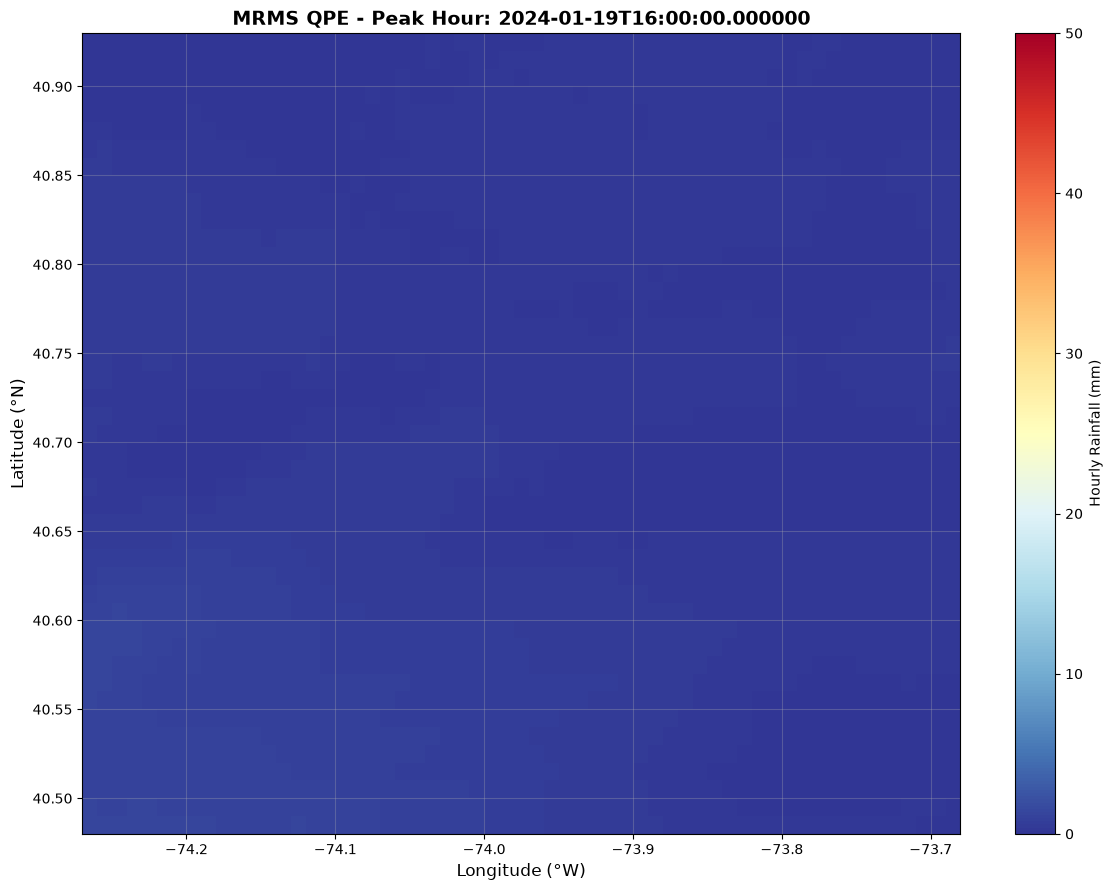

Peak precipitation: 1.3 mm at 2024-01-19T16:00:00.000000


In [3]:
if qpe is not None and qpe.values.max() > 0.1:
    # Pick peak hour (max precipitation)
    peak_time = qpe.where(qpe == qpe.max(), drop=True).time.values[0]
    field = qpe.sel(time=peak_time)
    
    fig, ax = plt.subplots(figsize=(12, 9))
    
    # Use OpenSense-style colormap: blue (light) → green → yellow → red (intense)
    # RdYlBu_r: Red-Yellow-Blue reversed (red for high values)
    im = field.plot(ax=ax, cmap="RdYlBu_r", vmin=0, vmax=50, 
                     cbar_kwargs={"label": "Hourly Rainfall (mm)"})
    
    ax.set_title(f"MRMS QPE - Peak Hour: {peak_time}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Longitude (°W)", fontsize=12)
    ax.set_ylabel("Latitude (°N)", fontsize=12)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"Peak precipitation: {float(field.max()):.1f} mm at {peak_time}")
else:
    if qpe is not None:
        print(f"✗ No significant rain/snow found (max = {qpe.values.max():.2f} mm)")
        print("Try a different date: 2024-01-19 (snow), 2024-03-23 (rain), 2024-02-13 (mixed)")
    else:
        print("✗ No data loaded")

## 2. Fetch KOKX NEXRAD Data

NEXRAD Level III products: hydrometeor class (HHC), reflectivity (N0B), etc.

In [4]:
from fetch_data.nexrad import kokx

# Fetch KOKX for same date as MRMS
start = "2024-01-19"
end = "2024-01-20"
products = ["HHC", "N0B"]  # Hydrometeor class, reflectivity

print(f"Fetching KOKX {products} for {start}...")
print("(This downloads from AWS and may take a few minutes on first run)")

try:
    kokx.fetch_window(start, end, products=products, workers=4)
    print("✓ Fetch complete")
except Exception as e:
    print(f"✗ Fetch failed: {e}")

Fetching KOKX ['HHC', 'N0B'] for 2024-01-19...
(This downloads from AWS and may take a few minutes on first run)


/Users/drorjac/miniforge3/envs/openmesh/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Fetch complete


### Load KOKX samples

In [5]:
# Load cached KOKX data
hhc = kokx.load(start, end, "HHC")
n0b = kokx.load(start, end, "N0B")

if hhc is not None:
    print(f"✓ HHC (Hydrometeor class): {len(hhc)} samples")
    print(f"  Times: {hhc['t'].min()} to {hhc['t'].max()}")
    print(f"  Columns: {list(hhc.columns)}")
    print(f"\n  Sample:")
    print(hhc.head())
else:
    print("✗ No HHC data (check date or run fetch above)")

if n0b is not None:
    print(f"\n✓ N0B (Reflectivity): {len(n0b)} samples")
    print(f"  Range: {n0b['value'].min():.1f} to {n0b['value'].max():.1f} dBZ")
else:
    print("\n✗ No N0B data")

✓ HHC (Hydrometeor class): 278352 samples
  Times: 2024-01-19 00:02:50 to 2024-01-19 23:51:08
  Columns: ['t', 'key', 'pt', 'value']

  Sample:
                    t key  pt  value
0 2024-01-19 00:02:50   1   0    0.0
1 2024-01-19 00:02:50   1   1    0.0
2 2024-01-19 00:02:50   1   2    0.0
3 2024-01-19 00:02:50   1   3    0.0
4 2024-01-19 00:02:50   1   4    0.0

✓ N0B (Reflectivity): 278352 samples
  Range: -9.5 to 28.0 dBZ


AttributeError: Rectangle.set() got an unexpected keyword argument 'colorbar'

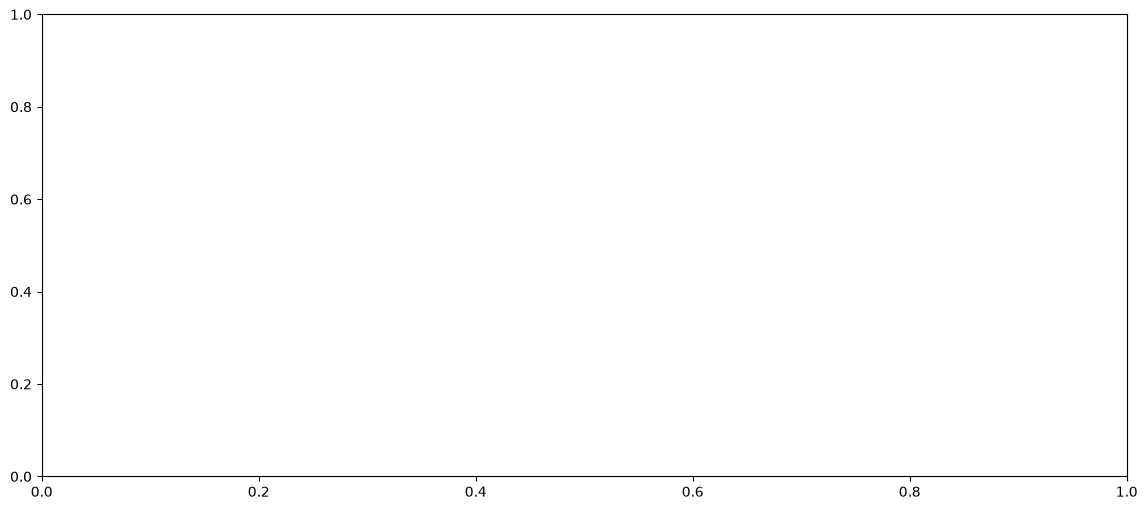

In [6]:
if hhc is not None:
    from fetch_data.nexrad.kokx import HYDRO_LEGEND
    
    # Create a pivot table: time vs link, with hydrometeor class
    pivot = hhc.pivot_table(values='value', index='t', columns='key', aggfunc='mean')
    
    # Focus on one time step with good data
    if len(pivot) > 0:
        # Pick a time with valid data
        time_idx = pivot.index[len(pivot)//2]  # Middle of period
        sample_time = pivot.loc[time_idx]
        
        fig, ax = plt.subplots(figsize=(12, 6))
        
        # Viridis colormap: dark blue (low) → green → yellow → bright (high)
        sample_time.dropna().plot(kind='bar', ax=ax, cmap='viridis', 
                                   figsize=(14, 6), colorbar=True)
        
        ax.set_title(f"KOKX HHC by Link: {time_idx}\n(Hydrometeor Class)", 
                     fontsize=14, fontweight='bold')
        ax.set_xlabel("Link ID", fontsize=12)
        ax.set_ylabel("Class Code", fontsize=12)
        ax.legend(title="Hydrometeor Class", bbox_to_anchor=(1.05, 1), loc='upper left')
        
        plt.tight_layout()
        plt.show()
        
        print(f"\nHydrometeor classes at {time_idx}:")
        for code, name in HYDRO_LEGEND.items():
            count = (sample_time == code).sum()
            if count > 0:
                print(f"  {code}: {name} ({int(count)} samples)")
else:
    print("No KOKX HHC data available")

### Visualize Hydrometeor Class

## 3. Use Event Catalog

Pre-selected rain/snow events for easier batch fetching.

In [19]:
# Build event catalog from ASOS (top rain/snow/mix days)
print("Building event catalog from ASOS...")
print("(This reads OpenMesh sensor data and may take ~1 min)")

try:
    from fetch_data.radar_events import select
    select()
    print("✓ Event catalog built")
    
    # Read the catalog
    events_file = Path().resolve().parents[2] / "dataset" / "meta" / "radar_events.csv"
    events = pd.read_csv(events_file, index_col="day", parse_dates=["day"])
    print(f"\nTop rain/snow events:")
    print(events[["kind", "asos_mm", "wet_minutes"]].head(10))
except Exception as e:
    print(f"✗ Could not build events: {e}")
    print("  (Need OpenMesh v1 or v2 data downloaded)")

Building event catalog from ASOS...
(This reads OpenMesh sensor data and may take ~1 min)


Failed to build daily summary: "No variable named 'rainfall'. Did you mean one of ('rainfall_rate', 'rainfall_amount')?"


✓ Event catalog built
✗ Could not build events: Missing column provided to 'parse_dates': 'day'
  (Need OpenMesh v1 or v2 data downloaded)


## 4. Command-line Tools

For batch processing, use the CLI:

In [20]:
print("""
# Fetch MRMS for all events
python src/fetch_data/radar_events.py fetch mrms

# Fetch KOKX for all events
python src/fetch_data/radar_events.py fetch kokx

# Fetch MRMS for one day
python src/fetch_data/radar_events.py fetch mrms --day 2024-01-09

# Fetch KOKX for one day
python src/fetch_data/radar_events.py fetch kokx --day 2024-01-09 --kind rain
""")


# Fetch MRMS for all events
python src/fetch_data/radar_events.py fetch mrms

# Fetch KOKX for all events
python src/fetch_data/radar_events.py fetch kokx

# Fetch MRMS for one day
python src/fetch_data/radar_events.py fetch mrms --day 2024-01-09

# Fetch KOKX for one day
python src/fetch_data/radar_events.py fetch kokx --day 2024-01-09 --kind rain



## 5. Reference: Products & Domains

**MRMS Products:**
- `MultiSensor_QPE_01H_Pass2` — 1-h gauge-corrected rainfall (best)
- `MultiSensor_QPE_01H_Pass1` — 1-h early estimate (~20 min latency)
- `RadarOnly_QPE_01H` — 1-h without gauge correction
- `PrecipFlag` — Type: rain/snow/hail/etc. (2-min)
- `PrecipRate` — Instantaneous rate (2-min)

**KOKX Products:**
- `HHC` — Hydrometeor class (dry snow, wet snow, rain, hail, graupel, etc.)
- `N0B` — Base reflectivity (dBZ, 0.25 km gates)
- `N0X` — Differential reflectivity (ZDR dB)
- `N0C` — Correlation coefficient

**Domains:**
- NYC: 40.48–40.93 N, -74.27–-73.68 W (MRMS)
- OpenMesh links: 40.57–40.86 N, -74.04–-73.88 W
- KOKX grid: 40.55–40.92 N, -74.10–-73.70 W

## 6. Tips

- **First fetch is slow** (downloads from AWS), subsequent fetches read from cache
- **Cache locations:**
  - MRMS: `dataset/raw/radar/mrms/cache/`
  - KOKX: `dataset/raw/radar/nexrad/cache/`
- **Network issues?** The code retries 3 times with backoff
- **Need different dates?** Just change `start` / `end` above
- **Missing dependencies?** Run `pip install -r requirements.txt` (includes metpy, eccodes)